# 11 · Actionable explanations for patients and clinicians
Notebook 04 found counterfactuals in **BMI units**. A patient cannot act on "lose 3 BMI points", so here we translate the explanations into the two audiences that matter in a screening programme:

- **Patient:** "if you lose *N kg* (and/or change X), the model would no longer flag you".
- **Clinician:** the main factors behind this person's score, plus the counterfactual options.

We use the **reduced model** (notebook 06: without `CholCheck`, `HvyAlcoholConsump`, `AnyHealthcare`), because a recommendation should not rely on data-collection shortcuts.

**Assumption on weight:** the dataset has BMI but no height. We convert with a *reference height* (women 1.61 m, men 1.75 m, approximate adult averages; `Sex=0` is female) using `kg = ΔBMI × height²`, and test how much the result depends on that choice. Individual advice would of course use the person's real height.
**Caveat (as always):** a counterfactual says what changes the *model's output*, not what would change the person's real risk.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings
from functools import partialmethod
from tqdm import tqdm; tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)
from src.preprocess import get_splits
from src.evaluation import threshold_for_recall
from src.counterfactuals import find_counterfactuals
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
red = joblib.load("../models/lightgbm_reduced.joblib")
keep = [c for c in X_tr.columns if c not in ["CholCheck", "HvyAlcoholConsump", "AnyHealthcare"]]
class Reduced:                     # lets the counterfactual search pass full rows
    def predict_proba(self, X): return red.predict_proba(X[keep])
model = Reduced()
thr = threshold_for_recall(y_va, red.predict_proba(X_va[keep])[:, 1], 0.80)
p_te = pd.Series(red.predict_proba(X_te[keep])[:, 1], index=X_te.index)
print(f"screening threshold (reduced model, recall >= 80% on validation) = {thr:.3f}")
HEIGHT = {0: 1.61, 1: 1.75}        # reference heights in metres by Sex (0 = female, 1 = male)
kg = lambda dBMI, sex, h=None: dBMI * (HEIGHT[int(sex)] if h is None else h) ** 2

screening threshold (reduced model, recall >= 80% on validation) = 0.147


## 1. Weight alone: how many kilos would take a flagged person below the threshold?
Same population as notebook 04 (flagged, but not extremely high risk; 200 random people). We keep every other variable fixed and lower only the BMI in 0.5-point steps (never below 18.5). This is the most "patient-friendly" counterfactual: one number.

In [2]:
cand = X_te[(p_te >= thr) & (p_te < 0.35)]
people = cand.sample(200, random_state=0)
def weight_only(x, step=0.5):
    z = x.astype(float).copy(); drops = np.arange(step, max(x.BMI - 18.5, 0) + 1e-9, step)
    if len(drops) == 0: return np.nan
    cand_ = pd.DataFrame([z.where(z.index != "BMI", x.BMI - d) for d in drops])
    ok = red.predict_proba(cand_[keep])[:, 1] < thr
    return drops[ok.argmax()] if ok.any() else np.nan
dB = people.apply(weight_only, axis=1)
w0 = people.BMI * people.Sex.map(HEIGHT) ** 2
res = pd.DataFrame({"dBMI": dB, "kg": [kg(d, s) for d, s in zip(dB, people.Sex)], "W0": w0}); res["pct"] = 100 * res.kg / res.W0
ok = res.dropna()
print(f"people analysed: {len(res)} | weight alone is enough for {len(ok)} ({len(ok)/len(res):.0%})")
print(ok[["dBMI", "kg", "pct"]].describe().round(1).loc[["25%", "50%", "75%"]])
print(f"share of those needing <= 7% of body weight (the Diabetes Prevention Program goal): {(ok.pct <= 7).mean():.0%}")

people analysed: 200 | weight alone is enough for 182 (91%)
     dBMI    kg   pct
25%   2.5   7.7   8.7
50%   4.5  13.8  16.1
75%   7.5  22.0  25.0
share of those needing <= 7% of body weight (the Diabetes Prevention Program goal): 20%


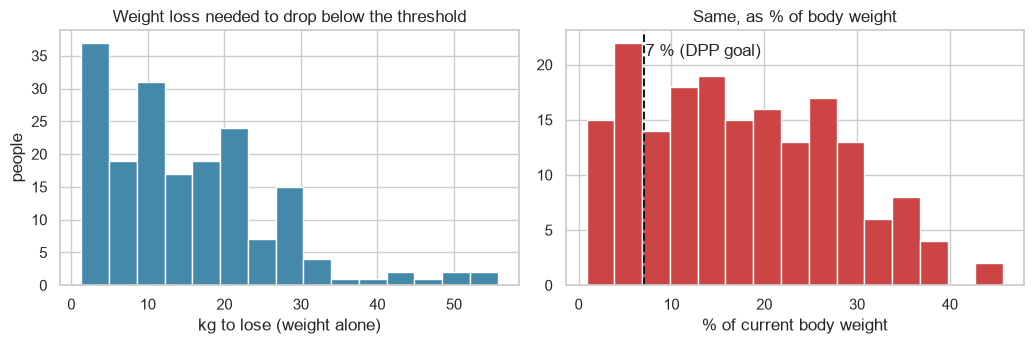

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.6))
ax[0].hist(ok.kg, bins=15, color="#48a"); ax[0].set_xlabel("kg to lose (weight alone)"); ax[0].set_ylabel("people"); ax[0].set_title("Weight loss needed to drop below the threshold")
ax[1].hist(ok.pct, bins=15, color="#c44"); ax[1].axvline(7, c="k", ls="--"); ax[1].text(7.2, ax[1].get_ylim()[1]*.9, "7 % (DPP goal)"); ax[1].set_xlabel("% of current body weight"); ax[1].set_title("Same, as % of body weight")
plt.tight_layout(); plt.savefig("../figures/action_kilos.png", dpi=150); plt.show()

### Sensitivity to the assumed height
The BMI drop is what the model sees, so the number of kilos scales with height². If real heights differ by ±10 cm from the reference, the median changes as follows.

In [4]:
rows = []
for dh in (-0.10, 0, 0.10):
    k = [kg(d, s, HEIGHT[int(s)] + dh) for d, s in zip(ok.dBMI, people.loc[ok.index].Sex)]
    rows.append({"height offset": f"{dh:+.2f} m", "median kg": np.median(k).round(1)})
pd.DataFrame(rows)

,height offset,median kg
0,-0.10 m,12.3
1,+0.00 m,13.8
2,+0.10 m,15.4


## 2. Three patient-style messages, with a clinician view
Three people chosen deterministically from the sample (low, middle and high BMI among those for whom weight alone is enough, plus one for whom it is not). For each: the options from the counterfactual search (fewest changes first), translated to kilos, and the five factors that contribute most to the score (SHAP, interventional, 100-row background).

In [5]:
bg = X_tr[keep].sample(100, random_state=0)
expl = shap.TreeExplainer(red, data=bg, feature_perturbation="interventional", model_output="raw")
PHRASE = {"HighBP": "no longer has high blood pressure (needs treatment)", "HighChol": "no longer has high cholesterol (needs treatment)",
          "Smoker": "stops smoking", "PhysActivity": "starts regular physical activity", "Fruits": "eats fruit daily", "Veggies": "eats vegetables daily"}
age_band = lambda k: "18-24" if k == 1 else ("80+" if k == 13 else f"{25+5*(int(k)-2)}-{29+5*(int(k)-2)}")
def patient_card(i):
    x = people.loc[i]; sex = int(x.Sex); w = x.BMI * HEIGHT[sex] ** 2
    cfs = find_counterfactuals(model, x, thr, k=3)
    lines = [f"Person {i}: {'woman' if sex == 0 else 'man'}, age {age_band(x.Age)}, BMI {x.BMI:.0f} (~{w:.0f} kg at {HEIGHT[sex]:.2f} m), model score {p_te[i]:.0%} (screening threshold {thr:.0%})"]
    wo = weight_only(x)
    lines.append("  Weight alone: " + (f"lose ~{kg(wo, sex):.0f} kg ({100*kg(wo, sex)/w:.0f}% of body weight)" if wo == wo else "not enough"))
    for j, r in cfs.iterrows():
        parts = [PHRASE[f] for f in r.changed]
        if r.bmi_drop: parts.append(f"lose ~{kg(r.bmi_drop, sex):.0f} kg")
        lines.append(f"  Option {j+1}: " + "; ".join(parts) + f"  -> score {r.p_after:.0%}")
    sv = pd.Series(expl(people.loc[[i], keep]).values[0], index=keep).sort_values(key=abs, ascending=False).head(5)
    lines.append("  Clinician view, top contributions to the log-odds: " + ", ".join(f"{f}={x[f]:.0f} ({v:+.2f})" for f, v in sv.items()))
    return "\n".join(lines)
sel = ok.sort_index().sort_values("kg", kind="stable"); chosen = [sel.index[len(sel)//10], sel.index[len(sel)//2], sel.index[-len(sel)//10]]
none = res[res.dBMI.isna()].index
if len(none): chosen.append(none[0])
for i in chosen: print(patient_card(i), "\n")

Person 108741: woman, age 65-69, BMI 27 (~70 kg at 1.61 m), model score 17% (screening threshold 15%)
  Weight alone: lose ~4 kg (6% of body weight)
  Option 1: no longer has high blood pressure (needs treatment)  -> score 8%
  Option 2: no longer has high cholesterol (needs treatment)  -> score 10%
  Option 3: lose ~5 kg  -> score 14%
  Clinician view, top contributions to the log-odds: HighBP=1 (+0.39), Age=10 (+0.38), GenHlth=2 (-0.33), HighChol=1 (+0.32), Income=4 (+0.18) 

Person 156188: man, age 65-69, BMI 28 (~86 kg at 1.75 m), model score 21% (screening threshold 15%)
  Weight alone: lose ~14 kg (16% of body weight)
  Option 1: lose ~15 kg  -> score 14%
  Option 2: no longer has high cholesterol (needs treatment); lose ~3 kg  -> score 13%
  Option 3: stops smoking; lose ~15 kg  -> score 14%
  Clinician view, top contributions to the log-odds: Age=10 (+0.44), GenHlth=3 (+0.30), HighBP=0 (-0.28), HighChol=1 (+0.24), Sex=1 (+0.16) 

Person 120238: man, age 60-64, BMI 30 (~92 kg at

In [6]:
# Do we need weight loss at all? Up to 30 options per person (one per set of binary changes).
n_cf = n_nolose = 0; mixed_kg = []
for i, x in people.iterrows():
    cf = find_counterfactuals(model, x, thr, k=30)
    if not len(cf): continue
    n_cf += 1; n_nolose += int((cf.bmi_drop == 0).any())
    m = cf[(cf.bmi_drop > 0) & (cf.changed.map(len) > 0)]
    if len(m): mixed_kg.append(m.bmi_drop.min() * HEIGHT[int(x.Sex)] ** 2)
print(f"people with >=1 counterfactual: {n_cf}; with an option needing NO weight loss: {n_nolose} ({n_nolose/n_cf:.0%})")
print(f"people with a mixed option (weight + another lever): {len(mixed_kg)}; median smallest weight loss = {np.median(mixed_kg):.1f} kg")

people with >=1 counterfactual: 198; with an option needing NO weight loss: 129 (65%)
people with a mixed option (weight + another lever): 173; median smallest weight loss = 6.1 kg


## 3. What this tells us
- For **91 %** of the 200 flagged people, weight loss alone can bring the score under the threshold, but the median amount is **~14 kg (~16 % of body weight)**, and only **20 %** of them would need ≤ 7 %, the weight loss goal of the Diabetes Prevention Program (Knowler et al., 2002). So "just lose weight" is realistic for some patients and a very large ask for most.
- Combining levers helps a lot. Of the 198 people with at least one counterfactual, **129 (65 %)** have an option that needs *no* weight loss at all (e.g. no longer having high blood pressure), and for the 173 with an option that mixes weight loss with another lever the smallest weight loss has a median of **~6 kg**. For the clinician, the explanation points at *clinical levers*, not only at lifestyle.
- Conditions such as `HighBP`/`HighChol` are not something a patient "switches off"; the counterfactual means "a person like this one, but without the condition", which in practice means diagnosis and treatment. We word it that way on purpose.
- The kilos depend on an assumed height (about ±1.5 kg in the median for ±10 cm). Real use would take the actual height.
- Still a statement about the **model**, not a causal effect: nothing here shows that losing weight lowers *this* person's risk by that amount.